# Elliptic Bitcoin graph EDA

Explore node/edge counts, degree distribution, label distribution, illicit rate over time, the three-way split, feature quality, and (optionally) a t-SNE of the GNN embeddings.

**Place the three CSVs under `data/raw/` before running.**

In [1]:
import sys
from pathlib import Path

def find_root(start):
    for p in [start, *start.parents]:
        if (p / 'src').exists():
            return p
    return start

ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import config
from src.dataset import load_elliptic

%matplotlib inline

C:\Users\86178\Desktop\gnn-fraud-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\86178\Desktop\gnn-fraud-detection\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
data = load_elliptic()  # prints the data summary

print(f'nodes: {data.num_nodes:,}')
print(f'edges (undirected): {data.edge_index.shape[1]:,}')
print(f'feature dim: {data.x.shape[1]}')
print(f'avg degree: {data.edge_index.shape[1] / data.num_nodes:.2f}')

Data summary
  nodes: 203,769    edges (undirected): 468,710
  feature dim: 165
  train: labeled  26,381 | illicit  2,871 | licit  23,510
    val: labeled   3,513 | illicit    591 | licit   2,922
   test: labeled  16,670 | illicit  1,083 | licit  15,587
nodes: 203,769
edges (undirected): 468,710
feature dim: 165
avg degree: 2.30


isolated nodes (deg=0): 0 (0.0%)


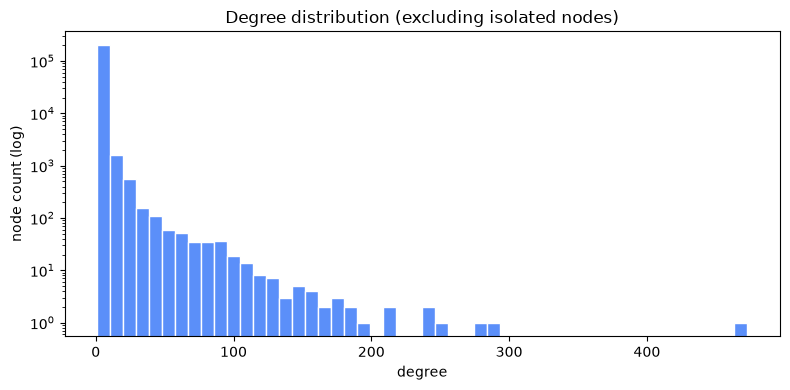

In [3]:
# degree distribution (including the isolated-node count)
deg = torch.bincount(data.edge_index[0], minlength=data.num_nodes).numpy()
isolated = int((deg == 0).sum())
print(f'isolated nodes (deg=0): {isolated:,} ({isolated/data.num_nodes:.1%})')

plt.figure(figsize=(8, 4))
plt.hist(deg[deg > 0], bins=50, color='#5b8ff9', edgecolor='white')
plt.yscale('log')
plt.xlabel('degree')
plt.ylabel('node count (log)')
plt.title('Degree distribution (excluding isolated nodes)')
plt.tight_layout()
plt.show()

In [4]:
# label distribution (the model is trained on the labeled subset)
y = data.y.numpy()
labels, counts = np.unique(y, return_counts=True)
name = {-1: 'unknown', 0: 'licit', 1: 'illicit'}
for l, c in zip(labels, counts):
    print(f'{name[l]:>10}: {c:,} ({c/len(y):.2%})')
labeled = y != -1
print()
print(f'illicit share among labeled: {(y==1).sum()/labeled.sum():.2%}  <- the ratio used for class weighting')

   unknown: 157,205 (77.15%)
     licit: 42,019 (20.62%)
   illicit: 4,545 (2.23%)

illicit share among labeled: 9.76%  <- the ratio used for class weighting


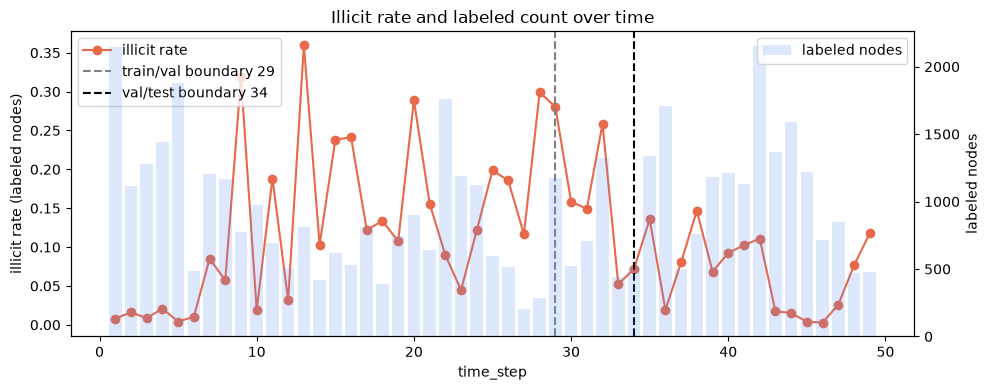

In [5]:
# illicit rate over time
ts = data.time_step.numpy()
labeled = y != -1
rows = []
for t in range(1, 50):
    m = labeled & (ts == t)
    n = int(m.sum())
    if n:
        rows.append((t, (y[m] == 1).sum() / n, n))
df = pd.DataFrame(rows, columns=['time_step', 'illicit_rate', 'n_labeled'])

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(df['time_step'], df['illicit_rate'], marker='o', color='#e8684a', label='illicit rate')
ax1.axvline(config.TRAIN_TS_END, color='grey', ls='--', label=f'train/val boundary {config.TRAIN_TS_END}')
ax1.axvline(config.VAL_TS_END, color='black', ls='--', label=f'val/test boundary {config.VAL_TS_END}')
ax1.set_xlabel('time_step')
ax1.set_ylabel('illicit rate (labeled nodes)')
ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.bar(df['time_step'], df['n_labeled'], alpha=0.2, color='#5b8ff9', label='labeled nodes')
ax2.set_ylabel('labeled nodes')
ax2.legend(loc='upper right')
plt.title('Illicit rate and labeled count over time')
plt.tight_layout()
plt.show()

In [6]:
# three-way split counts
def cnt(mask, val):
    return int(((data.y == val) & mask).sum())
print(f'{"split":>6} {"labeled":>9} {"illicit":>8} {"licit":>8}')
for nm, m in [('train', data.train_mask), ('val', data.val_mask), ('test', data.test_mask)]:
    print(f'{nm:>6} {int(m.sum()):>9,} {cnt(m,1):>8,} {cnt(m,0):>8,}')

 split   labeled  illicit    licit
 train    26,381    2,871   23,510
   val     3,513      591    2,922
  test    16,670    1,083   15,587


In [7]:
# feature quality scan (NaN / all-zero columns)
x = data.x.numpy()
print(f'feature matrix: {x.shape}')
print(f'NaN count: {int(np.isnan(x).sum())}')
allzero = [i for i in range(x.shape[1]) if np.allclose(x[:, i], 0.0)]
print(f'all-zero columns (originally constant): {len(allzero)}')

feature matrix: (203769, 165)
NaN count: 0
all-zero columns (originally constant): 0


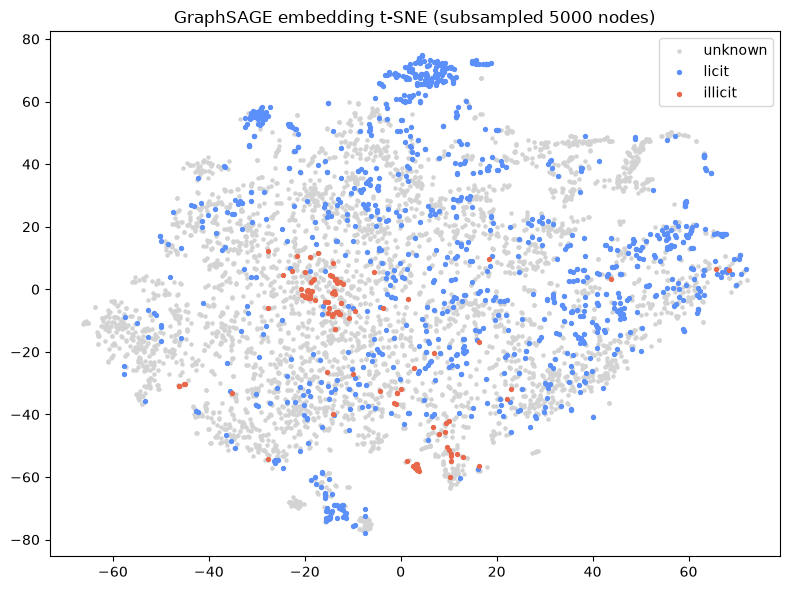

In [8]:
# optional: t-SNE of GNN embeddings (requires a saved model from `python -m src.main`)
from sklearn.manifold import TSNE
from src.models import build_model

name = 'GraphSAGE'  # best model by PR-AUC; also try GCN / GAT
ckpt = config.MODEL_DIR / f'{name}.pt'

if not ckpt.exists():
    print(f'no checkpoint at {ckpt}; run python -m src.main first')
else:
    model = build_model(name, data.x.shape[1], config.HIDDEN_DIM,
                        config.NUM_LAYERS, config.DROPOUT, config.GAT_HEADS)
    model.load_state_dict(torch.load(ckpt, map_location='cpu'))
    model.eval()
    with torch.no_grad():
        emb = model.embed(data.x, data.edge_index).numpy()

    rng = np.random.RandomState(0)
    idx = rng.choice(len(emb), size=min(5000, len(emb)), replace=False)
    emb2 = TSNE(n_components=2, random_state=0, init='pca', learning_rate='auto').fit_transform(emb[idx])
    yy = data.y.numpy()[idx]
    known = yy != -1

    plt.figure(figsize=(8, 6))
    plt.scatter(emb2[~known, 0], emb2[~known, 1], s=5, c='lightgrey', label='unknown')
    plt.scatter(emb2[known & (yy == 0), 0], emb2[known & (yy == 0), 1], s=8, c='#5b8ff9', label='licit')
    plt.scatter(emb2[known & (yy == 1), 0], emb2[known & (yy == 1), 1], s=8, c='#e8684a', label='illicit')
    plt.legend()
    plt.title(f'{name} embedding t-SNE (subsampled {len(idx)} nodes)')
    plt.tight_layout()
    plt.show()